# 계층 지도와 첫 호출

**이 노트북에서 할 일**

1. 모델 객체를 만드는 줄과 실제 요청을 보내는 줄을 나눠 실행합니다.
2. 역할과 내용을 묶은 메시지 목록을 보내고, 응답 객체에서 답과 사용량을 읽습니다.
3. 질문 하나, 출력 상한 하나를 바꿔 보고, 질문이 비어 있을 때 나는 오류를 고칩니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 없습니다.
인터넷 서비스의 모델 `gpt-5.4-mini`를 모두 4번 부릅니다. 실행 시간은 1분 안팎입니다.
예상 비용은 0.01달러 미만입니다(06절 4절에서 2026-09-17에 확인한 공식 요금 기준).

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
pydantic 2.13.5, python-dotenv 1.2.3도 함께 씁니다. 교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch06-langchain-start`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

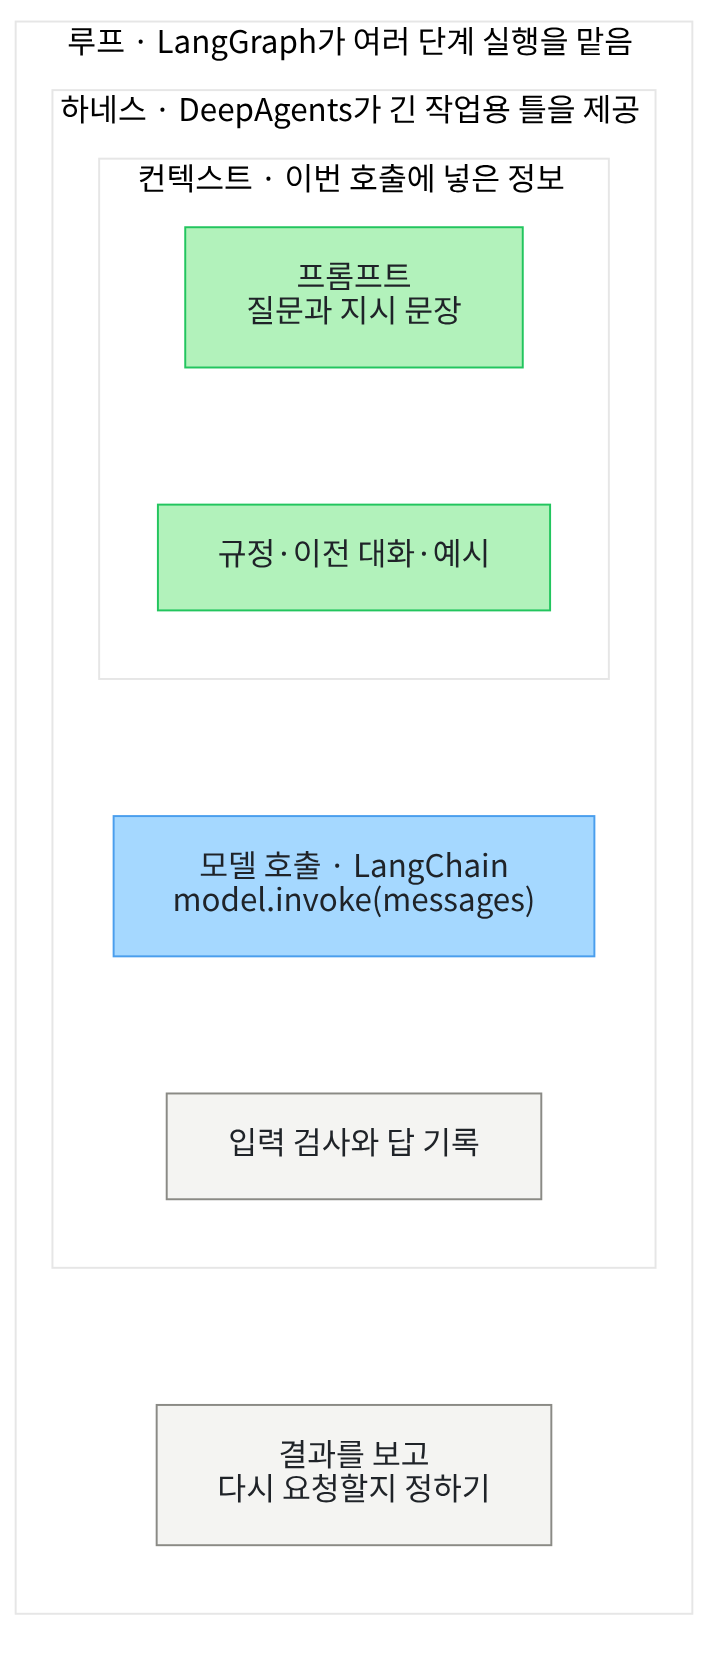

안쪽에서 바깥쪽으로 읽습니다. 가장 안쪽 초록 상자가 우리가 적은 프롬프트입니다.
바깥 칸으로 갈수록 이번 호출에 넣은 정보, 호출을 둘러싼 준비와 검사, 반복 흐름으로 범위가 넓어집니다.
이 노트북은 파란 상자 하나, 곧 LangChain으로 모델을 한 번 부르는 자리를 실행합니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
함수 `version()`은 패키지 이름을 받아 설치된 버전 글자를 반환합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "pydantic==2.13.5" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("pydantic:", version("pydantic"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
pydantic: 2.13.5


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `langchain-core: 1.6.2`, `langchain-openai: 1.6.0`, `pydantic: 2.13.5`입니다.
준비물에 적은 기준 버전과 같습니다. 패키지 langchain-core는 langchain을 설치할 때 함께 설치되는 기본 패키지입니다.

모델 객체를 만드는 함수를 불러옵니다. `from … import …` 모양은 Ch 2 07절에서 배웠습니다.

In [2]:
# 모델 객체를 만드는 함수를 불러옵니다
from langchain.chat_models import init_chat_model

API 키가 있는지 확인합니다. API 키는 서비스가 요청한 사람을 알아보는 비밀 글자입니다.
함수 `load_dotenv()`는 `.env` 파일의 줄을 환경 변수로 읽어 들입니다. 함수 `os.getenv()`는 그 이름의 값을 꺼내고, 없으면 `None`을 줍니다.

키 값은 출력하지 않고, 있는지만 봅니다. `True` 값이 나오면 다음으로 넘어갑니다.
Ch 3 01절처럼 `git status --short --ignored`로 `.env` 파일이 무시 규칙에 걸리는지도 확인합니다.
이 명령은 노트북 셀이 아니라 프로젝트 폴더의 터미널에서 실행합니다. 이 노트북은 그 결과를 출력하지 않습니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
함수 `init_chat_model()`은 모델 이름을 받아, 그 모델에 요청을 보낼 수 있는 모델 객체를 만듭니다.
전화기에 번호를 저장해 두는 일과 비슷합니다. 저장만 해서는 아직 전화가 걸리지 않습니다.
이름 `openai:gpt-5.4-mini`에서 콜론 앞은 모델을 제공하는 회사(제공자), 뒤는 모델 이름입니다.

temperature 값은 답을 고를 때의 무작위 정도이고, 0으로 두면 매번 비슷한 답을 고릅니다.
추론 설정 `reasoning_effort="none"`은 모델이 긴 추론 없이 바로 답하게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-16에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.

Ch 5 06절의 로컬 모델은 뽑기를 끈 설정(`do_sample=False`)으로 같은 컴퓨터에서 다시 실행하면 글자까지 같은 답을 냈습니다.
서비스 모델의 temperature 0은 그 설정과 같은 것이 아닙니다. 매번 비슷한 답을 고르지만, 똑같은 답을 보장하지는 않습니다.

## 2. 모델 객체는 아직 요청을 보내지 않았습니다

앞 셀은 모델 객체를 만들기만 했습니다. 이 셀에서 객체의 종류와 출력 상한을 확인합니다.
함수 `type()`은 값의 자료형을 알려 주고(Ch 2 01절), 뒤에 붙인 `__name__`은 자료형의 이름 글자만 꺼냅니다.
출력 상한은 모델이 한 번에 쓸 답의 토큰 수 상한입니다. 7절에서 이 값을 바꿔 봅니다.

실행 전에 예상합니다. 출력 상한은 따로 주지 않았으니 비어 있을 것입니다.

In [5]:
# 모델 객체의 종류와 출력 상한을 확인합니다(이 셀은 요청을 보내지 않습니다)
model_type = type(model).__name__
print("모델 객체 종류:", model_type)
print("출력 상한(max_tokens):", model.max_tokens)

모델 객체 종류: ChatOpenAI
출력 상한(max_tokens): None


**결과 읽기** — 출력 줄은 `모델 객체 종류: ChatOpenAI`와 `출력 상한(max_tokens): None`입니다.
제공자 이름 openai에 맞춰 OpenAI용 모델 객체가 만들어졌습니다. 예상대로 출력 상한은 `None`이라 따로 정하지 않았습니다.

## 3. 메시지 목록 만들기

메시지는 누가 한 말인지 역할 이름을 붙인 글 하나입니다. 여기서는 `(역할, 내용)` 튜플로 적습니다.
역할 system은 모든 질문에 공통으로 적용할 지시이고, 역할 user는 이번 질문입니다.
Ch 5 04절의 역할 딕셔너리 `{"role": "system", "content": …}`와 같은 역할·내용 묶음입니다.

튜플을 목록에 담은 순서가 모델에 전달되는 순서입니다. 반복문의 `for role, content in messages:`는 튜플을 두 이름에 풀어 담습니다(Ch 2 03절).

In [6]:
# 공통 지시(system)와 이번 질문(user)을 튜플로 묶어 목록에 담습니다
messages = [
    ("system", "두 문장 이내의 한국어로 답하세요."),
    ("user", "LangChain 모델 인터페이스의 장점을 한 가지 설명하세요."),
]
# 튜플을 역할과 내용으로 풀어 담아 한 줄에 하나씩 출력합니다
print("메시지 목록:")
for role, content in messages:
    print(role, "|", content)

메시지 목록:
system | 두 문장 이내의 한국어로 답하세요.
user | LangChain 모델 인터페이스의 장점을 한 가지 설명하세요.


**결과 읽기** — 라벨 줄 아래 첫 줄은 `system | 두 문장 이내의 한국어로 답하세요.`, 둘째 줄은 user 질문입니다.
아직 목록만 만들었고 요청은 보내지 않았습니다.

## 4. 첫 호출: invoke

메서드 `invoke()`는 메시지 목록을 받아 모델에 요청을 보내고, 완성된 답을 응답 객체로 반환합니다.
이 줄을 실행하는 순간 인터넷으로 요청이 한 번 나가고, 답이 올 때까지 셀이 실행 중으로 표시됩니다.
이 셀을 다시 실행하면 요청이 다시 나가고 사용량도 다시 생깁니다.

실행 전에 예상합니다. 응답 객체의 종류는 문자열이 아니라 LangChain의 메시지 객체일 것입니다.

In [7]:
# 메시지 목록을 모델에 보내고, 완성된 답을 응답 객체로 받습니다(요청 1번)
response = model.invoke(messages)
response_type = type(response).__name__
print("응답 객체 종류:", response_type)
# 속성 text는 응답 객체에서 답 글자만 꺼냅니다(뒤에 괄호를 붙이지 않습니다)
print("답:", response.text)

응답 객체 종류: AIMessage
답: LangChain 모델 인터페이스의 장점은 다양한 LLM을 같은 방식으로 다룰 수 있어, 모델을 바꿔도 코드 수정이 적다는 점입니다.


**결과 읽기** — 첫 줄은 `응답 객체 종류: AIMessage`입니다. 모델이 쓴 메시지를 담는 객체라는 뜻입니다.
둘째 줄은 `답: LangChain 모델 인터페이스의 장점은`으로 시작합니다. 답 문장은 실행마다 달라질 수 있습니다.

첫 줄은 Python이 확인한 객체 종류이고, 둘째 줄은 모델이 쓴 글입니다. 답 내용이 맞는지는 이번에 판정하지 않았습니다.
Ch 5 07절의 판정 규칙(새 숫자·보류 문장)은 숫자가 없는 주장을 놓치므로, 이런 설명 문장을 판정하지 못합니다.

## 5. 응답 객체 안의 사용량과 끝난 이유

응답 객체에는 답 글자 말고도 정보가 들어 있습니다. 속성 `usage_metadata`는 토큰 사용량을 담은 딕셔너리입니다.
속성 `response_metadata`는 제공자가 보낸 추가 정보 딕셔너리이고, 키 `"finish_reason"`에 답이 끝난 이유가 있습니다.
딕셔너리에서 키로 값을 꺼내는 모양은 Ch 2 03절에서 배웠습니다.

In [8]:
# 응답 객체에서 토큰 사용량과 답이 끝난 이유를 꺼냅니다
usage = response.usage_metadata
print("입력 토큰 수:", usage["input_tokens"])
print("출력 토큰 수:", usage["output_tokens"])
print("합계 토큰 수:", usage["total_tokens"])
print("끝난 이유:", response.response_metadata["finish_reason"])

입력 토큰 수: 36
출력 토큰 수: 41
합계 토큰 수: 77
끝난 이유: stop


**결과 읽기** — 출력 줄은 `입력 토큰 수: 36`, `출력 토큰 수: 41`, `합계 토큰 수: 77`입니다.
끝난 이유는 `stop`으로, 모델이 답을 다 쓰고 스스로 멈췄다는 뜻입니다.

토큰 수는 제공자의 토큰화기로 센 값입니다. Ch 5 01절에서 본 것처럼 토큰화기마다 수가 다르므로, Qwen 조각 수와 비교하지 않습니다.
입력 토큰 수에는 우리가 적은 두 메시지 말고도 제공자 쪽에서 붙인 표시가 들어갈 수 있습니다. 그 글은 서비스 모델에서는 보이지 않습니다.

## 6. 값 바꿔 보기 1 — 질문만 바꾸기

바꾸는 값은 user 질문 하나입니다. 모델 객체와 system 메시지 `messages[0]`은 그대로 씁니다.
새 목록에는 앞 답을 넣지 않았습니다. 그래서 이 호출은 앞 호출과 이어진 대화가 아니라 따로 보낸 요청입니다.

실행 전에 예상합니다. 답 문장은 달라지지만, 응답 객체 종류는 똑같이 AIMessage일 것입니다.

In [9]:
# system 메시지는 그대로 두고 user 질문만 바꿔 다시 보냅니다(요청 1번)
changed_messages = [
    messages[0],
    ("user", "LangChain 모델 인터페이스를 한 문장으로 설명하세요."),
]
changed = model.invoke(changed_messages)
changed_type = type(changed).__name__
print("응답 객체 종류:", changed_type)
print("답:", changed.text)

응답 객체 종류: AIMessage
답: LangChain 모델 인터페이스는 다양한 LLM과 채팅 모델을 일관된 방식으로 호출하고, 입력·출력·스트리밍을 표준화해 애플리케이션에 쉽게 연결할 수 있게 해주는 추상화 계층입니다.


**결과 읽기** — 첫 줄은 예상대로 `응답 객체 종류: AIMessage`입니다. 답 줄은 한 문장으로 바뀌었습니다.
질문을 바꿔도 `invoke()`로 보내고 `text`로 읽는 순서는 같았습니다.

## 7. 값 바꿔 보기 2 — 출력 상한을 12로 줄이기

바꾸는 값은 출력 상한 하나입니다. 인자 `max_tokens=12`를 준 모델 객체를 새로 만들고, 첫 호출과 같은 목록을 보냅니다.

출력 상한은 Ch 5 04절의 출력 몫(`max_new_tokens`)과 같은 뜻의 값입니다. Ch 5에서는 출력 몫 8에서 답이 오류 없이 끊겼습니다.
12는 끊기는 모습을 보려고 정한 값입니다. 교재를 만들 때 탐색 실행으로 끊기는 것을 먼저 확인한 뒤 정했습니다.

실행 전에 예상합니다. 첫 호출의 답은 12토큰보다 길었으니, 이번에는 답이 중간에 끊길 것입니다.

In [10]:
# 출력 상한만 12토큰으로 준 모델 객체를 새로 만듭니다(이 셀은 요청을 보내지 않습니다)
short_model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
    max_tokens=12,
)
print("출력 상한(max_tokens):", short_model.max_tokens)

출력 상한(max_tokens): 12


**결과 읽기** — 출력 줄은 `출력 상한(max_tokens): 12`입니다. 2절의 `None`과 달리 상한이 정해졌습니다.

같은 메시지 목록 `messages`를 새 모델 객체로 보냅니다. 답, 출력 토큰 수, 끝난 이유를 봅니다.

In [11]:
# 첫 호출과 같은 메시지 목록을 보내고, 답과 끝난 이유를 봅니다(요청 1번)
short_response = short_model.invoke(messages)
short_usage = short_response.usage_metadata
print("답:", short_response.text)
print("출력 토큰 수:", short_usage["output_tokens"])
print("끝난 이유:", short_response.response_metadata["finish_reason"])

답: LangChain 모델 인터페이스의 장점
출력 토큰 수: 12
끝난 이유: length


**결과 읽기** — 출력 줄은 `출력 토큰 수: 12`와 `끝난 이유: length`입니다. 답 줄은 문장 가운데서 끊겼습니다.
끝난 이유 `length`는 출력 상한에 닿아 멈췄다는 뜻입니다. 5절의 `stop`과 다릅니다.

오류는 나지 않았고, 끊긴 답이 응답 객체에 그대로 담겼습니다. Ch 5 04절의 출력 몫 8과 같은 모습입니다.
답 글자만 보면 끊긴 줄 모르고 넘어갈 수 있으니, 끝난 이유를 함께 확인합니다.

## 8. Before — 비어 있는 질문으로 호출하기

질문을 딕셔너리에서 이름으로 꺼내 쓴다고 해 봅니다. Ch 2 03절에서 배운 메서드 `get()`은 없는 키를 넣으면 `None`을 반환합니다.
그 `None`을 그대로 메시지 내용 자리에 넣으면 어떻게 되는지 봅니다.

실행 전에 예상합니다. 꺼낸 질문은 `None`이고, 메시지는 두 개일 것입니다.

In [12]:
# 질문 사전에 없는 이름으로 질문을 꺼내 메시지 목록을 만듭니다
questions = {"장점": "LangChain 모델 인터페이스의 장점을 한 가지 설명하세요."}
empty_question = questions.get("단점")
print("꺼낸 질문:", empty_question)
bad_messages = [messages[0], ("user", empty_question)]
print("메시지 개수:", len(bad_messages))

꺼낸 질문: None
메시지 개수: 2


**결과 읽기** — 출력 줄은 `꺼낸 질문: None`과 `메시지 개수: 2`입니다. 목록을 만들 때는 오류가 나지 않았습니다.

이 목록으로 호출합니다. LangChain 라이브러리는 튜플을 메시지 객체로 바꿀 때, 값의 모양을 Pydantic 라이브러리로 검사합니다.
택배 접수대가 주소 칸이 빈 송장을 받지 않는 것과 비슷합니다. 이 검사를 통과하지 못하면 `ValidationError`라는 오류가 납니다.

라이브러리 Pydantic과 이 오류 이름은 Ch 2 10절에서 자세히 다룹니다. 기본 경로(A 트랙)에서 그 절을 건너뛰었다면, 값의 모양이 틀렸다는 오류로만 알아 두면 됩니다.

오류 이름만 받는 `try/except 이름 as error:`는 Ch 2 05절 모양입니다. 받아서 출력하므로 셀은 끝까지 실행됩니다.
실행 전에 예상합니다. 내용 자리에 글자가 아닌 `None`이 있어 검사 오류가 날 것입니다.

In [13]:
# 내용이 None인 목록으로 호출하고, 값 검사 오류만 받아 출력합니다
from pydantic import ValidationError

try:
    bad_response = model.invoke(bad_messages)
    print("답:", bad_response.text)
except ValidationError as error:
    print("오류 종류:", type(error).__name__)
    print("오류 메시지:")
    print(error)

오류 종류: ValidationError
오류 메시지:
2 validation errors for HumanMessage
content.str
  Input should be a valid string [type=string_type, input_value=None, input_type=NoneType]
    For further information visit https://errors.pydantic.dev/2.13/v/string_type
content.list[union[str,dict[any,any]]]
  Input should be a valid list [type=list_type, input_value=None, input_type=NoneType]
    For further information visit https://errors.pydantic.dev/2.13/v/list_type


**결과 읽기** — 첫 줄은 `오류 종류: ValidationError`입니다. 라벨 줄 아래 오류 메시지는 `2 validation errors for HumanMessage`로 시작합니다.
그 아래 `Input should be a valid string` 줄은 내용이 글자여야 한다는 뜻입니다. 사람이 쓴 메시지 객체 이름이 HumanMessage입니다.

이 오류는 튜플을 메시지 객체로 바꾸는 단계에서 났습니다. 설치한 langchain-core 1.6.2 소스에서 이 단계가 요청 전이라는 것을 확인했습니다.
그래서 모델의 답이 틀린 것이 아니라, 요청을 보내기도 전에 입력이 거부된 것입니다. `try/except` 문장이 없으면 프로그램은 여기서 멈춥니다.

## 9. After — 질문이 비어 있지 않게 고치기

Ch 2 03절처럼 메서드 `get()`에 둘째 인자로 기본값을 주면, 없는 키일 때 그 기본값을 반환합니다.
바꾸는 곳은 `get()` 호출 한 줄입니다. 기본 질문은 모델에게 객체 이름을 말하게 하는 글로 정했습니다.

실행 전에 예상합니다. 꺼낸 질문이 기본 질문 글로 바뀔 것입니다.

In [14]:
# 없는 이름이면 기본 질문을 꺼내도록 get()에 기본값을 줍니다
default_question = "AIMessage라고만 답하세요."
filled_question = questions.get("단점", default_question)
print("꺼낸 질문:", filled_question)
fixed_messages = [messages[0], ("user", filled_question)]
print("메시지 개수:", len(fixed_messages))

꺼낸 질문: AIMessage라고만 답하세요.
메시지 개수: 2


**결과 읽기** — 출력 줄은 `꺼낸 질문: AIMessage라고만 답하세요.`와 `메시지 개수: 2`입니다.

같은 모델 객체와 같은 `invoke()`로 다시 보냅니다. 마지막 줄의 `assert`는 응답 객체 종류가 AIMessage인지 확인합니다.
답 문장은 실행마다 달라질 수 있어 `assert`로 확인하지 않고, 매번 같아야 하는 객체 종류만 확인합니다.

In [15]:
# 고친 목록을 같은 방법으로 보내고, 응답 객체 종류를 확인합니다(요청 1번)
fixed = model.invoke(fixed_messages)
fixed_type = type(fixed).__name__
print("답:", fixed.text)
print("응답 객체 종류:", fixed_type)
assert fixed_type == "AIMessage"

답: AIMessage
응답 객체 종류: AIMessage


**결과 읽기** — 출력 줄은 `답: AIMessage`와 `응답 객체 종류: AIMessage`입니다. `assert`도 통과했습니다.

두 줄의 글자는 같지만 뜻이 다릅니다. 첫 줄은 모델이 쓴 글이고, 둘째 줄은 Python이 확인한 객체 종류입니다.
객체 종류는 둘째 줄처럼 코드로 확인합니다. 모델에게 말하게 한 글은 확인 결과가 아닙니다.

## 정리

- 함수 `init_chat_model()`은 모델 객체만 만들고, 메서드 `invoke()`가 실제 요청을 보냅니다. 이번 노트북의 요청은 4번이었습니다.
- 응답 객체 `AIMessage`의 `text`에 답이, `usage_metadata`에 토큰 수가, `response_metadata`에 끝난 이유가 있습니다.
- 출력 상한 12에서는 답이 오류 없이 끊기고 끝난 이유가 `length`였습니다. 질문이 `None`이면 요청 전에 `ValidationError`가 났습니다.

다음 02절에서는 메시지를 메시지 객체로도 만들어 봅니다. 그리고 모델 이름과 제공자 이름을 바꿔, 그대로 되는 것과 다시 확인할 것을 나눕니다.